# Household Waste Generation Pattern Analysis
**Student:** TALLAPALLY SANJAY  
**Roll No.:** 160125737130  
**Subject:** EDAV — Course-End Project

## Introduction
Households produce different types of waste every day. Studying the quantity, category, location and date of waste can help us understand common patterns and plan better waste segregation and collection.

## Objective
To explore household waste data, clean the records, compare waste categories, study changes over time, and present the findings using tables and graphs.

**Dataset note:** The provided CSV is synthetic demonstration data. Replace it with real or instructor-approved data before submitting if required.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Import libraries
**Explanation:** NumPy supports numerical calculations, Pandas manages tables, and Matplotlib/Seaborn create graphs.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/household_waste_demo_dataset.csv")
df.head()

,date,household_id,area,household_size,category,quantity_kg,segregated
0,2026-07-01,H01,North,3,Organic,0.228,Yes
1,2026-07-01,H01,North,3,Recyclable,0.072,No
2,2026-07-01,H01,North,3,Non-recyclable,0.146,No
3,2026-07-01,H01,North,3,Hazardous,0.012,Yes
4,2026-07-01,H02,North,4,Organic,0.329,No


## 2. Explore the dataset
**Explanation:** First, inspect a few rows, the column types, basic statistics, missing values and duplicate records. This helps identify data-quality issues before analysis.

In [4]:
print("Rows and columns:", df.shape)
display(df.describe(include="all").T)
display(df.isna().sum().to_frame("Missing values"))
print("Duplicate rows:", df.duplicated().sum())

Rows and columns: (3600, 7)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,3600,60,2026-07-01,60,NaN,NaN,NaN,NaN,NaN,NaN,NaN
household_id,3600,15,H01,240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
area,3600,3,North,1200,NaN,NaN,NaN,NaN,NaN,NaN,NaN
household_size,3600.0,NaN,NaN,NaN,4.0,1.41441,2.0,3.0,4.0,5.0,6.0
category,3600,5,Organic,900,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity_kg,3599.0,NaN,NaN,NaN,0.166571,0.141245,0.004,0.0345,0.145,0.228,0.641
segregated,3599,2,No,1841,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Missing values
date,0
household_id,0
area,0
household_size,0
category,0
quantity_kg,1
segregated,1


Duplicate rows: 0


## 3. Clean the data
**Explanation:** Dates and quantities are converted to suitable data types. Text labels are trimmed and standardized. Rows without the date, category, household identifier or quantity are excluded from the main analysis. Missing segregation labels are marked as “Unknown” instead of guessing them.

In [5]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["quantity_kg"] = pd.to_numeric(df["quantity_kg"], errors="coerce")
df["category"] = df["category"].astype("string").str.strip().str.title()
df["segregated"] = df["segregated"].astype("string").str.strip().str.title()
df = df.drop_duplicates()
data = df.dropna(subset=["date", "category", "household_id", "quantity_kg"]).copy()
data["segregated"] = data["segregated"].fillna("Unknown")
data.head()

,date,household_id,area,household_size,category,quantity_kg,segregated
0,2026-07-01,H01,North,3,Organic,0.228,Yes
1,2026-07-01,H01,North,3,Recyclable,0.072,No
2,2026-07-01,H01,North,3,Non-Recyclable,0.146,No
3,2026-07-01,H01,North,3,Hazardous,0.012,Yes
4,2026-07-01,H02,North,4,Organic,0.329,No


## 4. Summary of waste quantity
**Explanation:** NumPy calculates the total, average, minimum and maximum recorded quantities. Missing quantities are not treated as zero because that would distort the results.

In [6]:
q = data["quantity_kg"].to_numpy()
print("Total:", round(np.sum(q), 2), "kg")
print("Average per record:", round(np.mean(q), 3), "kg")
print("Minimum:", round(np.min(q), 3), "kg")
print("Maximum:", round(np.max(q), 3), "kg")

Total: 599.49 kg
Average per record: 0.167 kg
Minimum: 0.004 kg
Maximum: 0.641 kg


## 5. Compare waste categories
**Explanation:** Grouping records by category shows which category contributes the most to the recorded total. The bar chart makes the comparison easier to understand.

,Total quantity (kg)
category,
Organic,314.05
Non-Recyclable,152.28
Recyclable,118.35
Hazardous,14.81


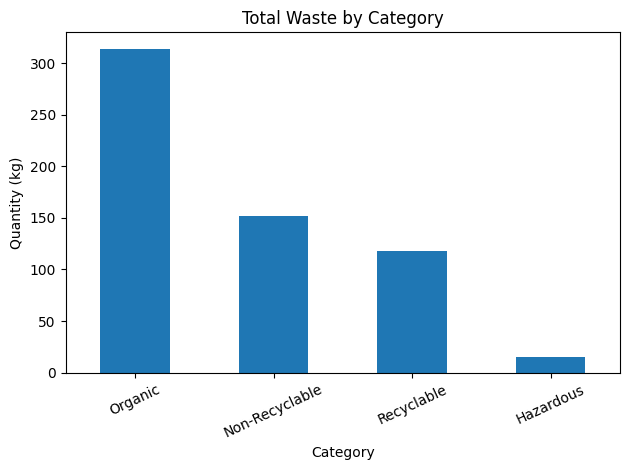

In [7]:
category_total = data.groupby("category")["quantity_kg"].sum().sort_values(ascending=False)
display(category_total.to_frame("Total quantity (kg)").round(2))
category_total.plot(kind="bar", title="Total Waste by Category", ylabel="Quantity (kg)", xlabel="Category", rot=25)
plt.tight_layout()
plt.show()

## 6. Compare areas
**Explanation:** Grouping by area helps compare the recorded waste totals across locations. These differences describe this dataset and do not, by themselves, explain why one area differs from another.

,Total quantity (kg)
area,
South,200.53
Central,199.95
North,199.01


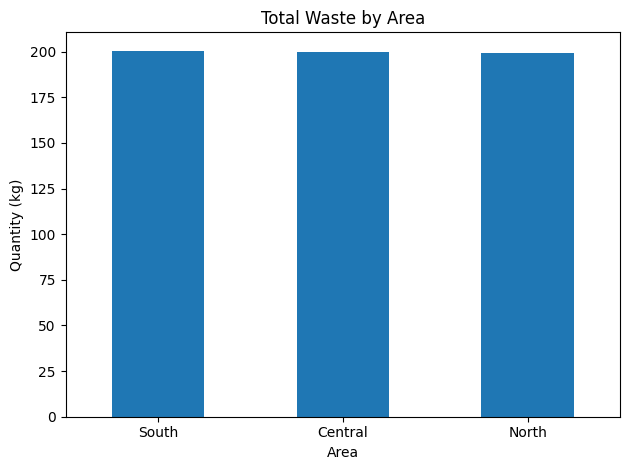

In [8]:
area_total = data.groupby("area")["quantity_kg"].sum().sort_values(ascending=False)
display(area_total.to_frame("Total quantity (kg)").round(2))
area_total.plot(kind="bar", title="Total Waste by Area", ylabel="Quantity (kg)", xlabel="Area", rot=0)
plt.tight_layout()
plt.show()

## 7. Study waste over time
**Explanation:** Converting dates into datetime format allows us to arrange records in time order. Resampling combines daily records into weekly totals, making broader trends easier to see.

,Weekly total (kg)
date,
2026-07-05,50.85
2026-07-12,69.99
2026-07-19,69.40
2026-07-26,69.47
2026-08-02,69.59
2026-08-09,70.12
2026-08-16,70.12
2026-08-23,70.18
2026-08-30,59.76


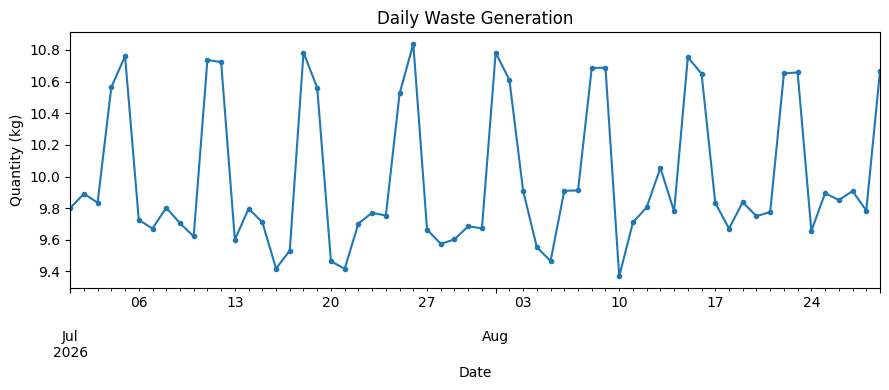

In [9]:
daily = data.groupby("date")["quantity_kg"].sum().sort_index()
weekly = daily.resample("W").sum()
display(weekly.to_frame("Weekly total (kg)").round(2))
daily.plot(kind="line", marker=".", title="Daily Waste Generation", ylabel="Quantity (kg)", xlabel="Date", figsize=(9, 4))
plt.tight_layout()
plt.show()

## 8. Household size and waste
**Explanation:** This scatter plot compares household size with the total recorded waste for each household-day. It can show a relationship, but it cannot prove that household size is the only factor affecting waste.

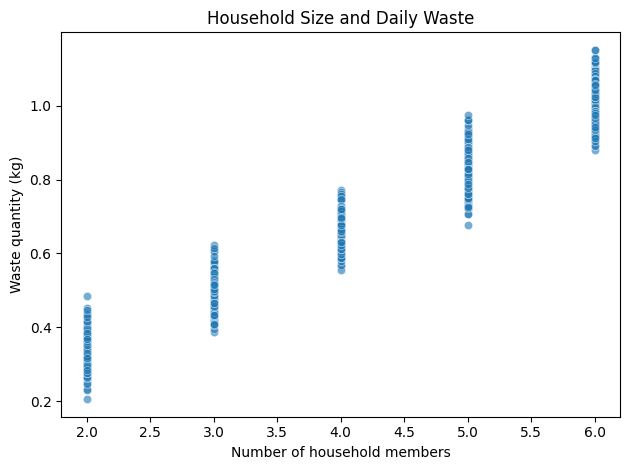

In [10]:
daily_household = data.groupby(["date", "household_id", "household_size"], as_index=False)["quantity_kg"].sum()
sns.scatterplot(data=daily_household, x="household_size", y="quantity_kg", alpha=0.6)
plt.title("Household Size and Daily Waste")
plt.xlabel("Number of household members")
plt.ylabel("Waste quantity (kg)")
plt.tight_layout()
plt.show()

## 9. Waste segregation
**Explanation:** Comparing recorded quantities by category and segregation status gives a simple view of how the records are distributed. The chart should be interpreted as an association, not proof that segregation caused a particular quantity.

segregated,No,Unknown,Yes
category,,,
Hazardous,0.016,NaN,0.017
Non-Recyclable,0.170,NaN,0.169
Organic,0.348,0.548,0.349
Recyclable,0.131,NaN,0.132


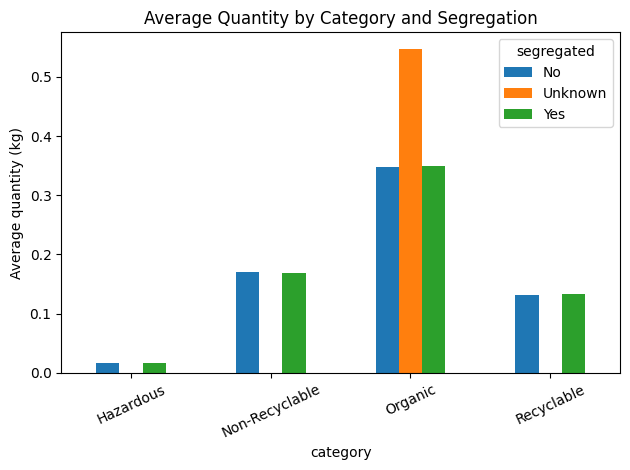

In [11]:
seg_summary = data.groupby(["category", "segregated"])["quantity_kg"].mean().unstack()
display(seg_summary.round(3))
seg_summary.plot(kind="bar", title="Average Quantity by Category and Segregation", ylabel="Average quantity (kg)", rot=25)
plt.tight_layout()
plt.show()

## 10. Final conclusion
Complete this section after checking the outputs, especially if you replace the demonstration data.

- **Main waste category:** [write the category with the highest total]
- **Area comparison:** [summarize the area totals]
- **Time pattern:** [describe what the daily and weekly results show]
- **Household size:** [describe the scatter plot]
- **Data quality:** [mention missing values or inconsistent labels found]
- **Recommendation:** [suggest a practical improvement supported by your results]

## Limitations
The provided dataset is synthetic and should not be presented as a real household survey. Results from any dataset depend on the quality, size and time period of the data collected.